<a href="https://colab.research.google.com/github/Saniya-Nawaz/Sentiment_Analysis/blob/main/Sentiment_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [ ]:
from google.colab import files
import pandas as pd

uploaded = files.upload()

Saving train.xlsx to train.xlsx


In [ ]:
df = pd.read_excel("train.xlsx")

df.head()

,Reviews,Sentiment
0,"When I first tuned in on this morning news, I ...",neg
1,"Mere thoughts of ""Going Overboard"" (aka ""Babes...",neg
2,Why does this movie fall WELL below standards?...,neg
3,Wow and I thought that any Steven Segal movie ...,neg
4,"The story is seen before, but that does'n matt...",neg


In [ ]:
df.shape

(25000, 2)

In [ ]:
df.columns

Index(['Reviews', 'Sentiment'], dtype='object')

In [ ]:
df.isnull().sum()

,0
Reviews,0
Sentiment,0


In [ ]:
df["Sentiment"].value_counts()

,count
Sentiment,
neg,12500
pos,12500


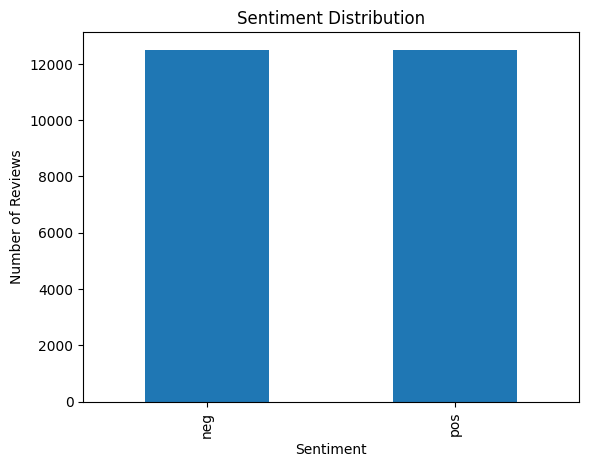

In [ ]:
df["Sentiment"].value_counts().plot(kind="bar")

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()

In [ ]:

X = df["Reviews"].astype(str)
y = df["Sentiment"]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
vectorizer = TfidfVectorizer()

In [ ]:
X_train_tfidf = vectorizer.fit_transform(X_train)

In [ ]:
X_test_tfidf = vectorizer.transform(X_test)

In [ ]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train_tfidf, y_train)

LogisticRegression(max_iter=1000)

In [ ]:
y_pred = model.predict(X_test_tfidf)

In [ ]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.8902


In [ ]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

         neg       0.90      0.87      0.89      2500
         pos       0.88      0.91      0.89      2500

    accuracy                           0.89      5000
   macro avg       0.89      0.89      0.89      5000
weighted avg       0.89      0.89      0.89      5000



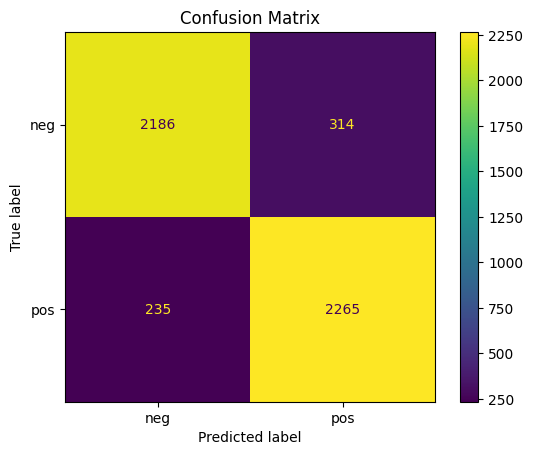

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)

disp.plot()
plt.title("Confusion Matrix")
plt.show()

In [ ]:
review = input("Enter a review: ")

review_tfidf = vectorizer.transform([review])

prediction = model.predict(review_tfidf)

print("Predicted Sentiment:", prediction[0])

Enter a review: terrible experience
Predicted Sentiment: neg


In [ ]:
probability = model.predict_proba(review_tfidf)

print("Sentiment:", prediction[0])
print("Confidence:", round(max(probability[0]) * 100, 2), "%")

Sentiment: neg
Confidence: 92.45 %
